# Análisis Descriptivo — Base de Clientes y Transacciones

## Objetivo
Realizar un análisis descriptivo de las variables cuantitativas y cualitativas de la base de datos, enfocado en la **toma de decisiones** y la **caracterización de la población**.

### Contenido del análisis:
1. **Carga y exploración inicial** de los datos
2. **Variables cuantitativas**: estadísticas, distribuciones e insights
3. **Variables cualitativas**: frecuencias, moda y perfil de la población
4. **Análisis cruzado** para decisiones estratégicas
5. **Conclusiones y recomendaciones**

## 1. Configuración e importación de librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('ggplot')
sns.set_palette("husl")
%matplotlib inline

# Evitar notación científica en números
pd.options.display.float_format = '{:.2f}'.format

## 2. Carga y exploración inicial de los datos

In [2]:
# Cargar datos (header en fila 1, ya que fila 0 es título)
df = pd.read_excel('base_final_clase.xlsx', header=1)

print("Dimensiones de la base:", df.shape)
print("\nPrimeras filas:")
df.head()

Dimensiones de la base: (3284, 24)

Primeras filas:


,transaction_id,key_user,date,time,channel,category,amount_usd,payment_method,full_name,identification,...,Nivel_educativo,Ocupación,Profesión,Estado_civil,Tamaño_hogar,Ciclo_vida_familiar,Religión,Nacionalidad,Origen_étnico,Generación
0,T002209,KU1335,2025-12-15,08:30,Online,Hogar,431.68,Débito,Valentina Rojas,23557329,...,Bachiller,Empresario,Médico,Unión libre,4,Joven soltero,Agnóstico,Peruana,Blanco,Gen X
1,T001085,KU1164,2024-08-18,21:50,Online,Electrónica,557.37,Débito,Juliana García,65928436,...,Bachiller,Independiente,Diseñador,Soltero,5,Familia con hijos,Ateo,Argentina,Indígena,Gen Z
2,T001656,KU1247,2025-03-02,18:50,Online,Electrónica,85.57,Efectivo,Camila Rodríguez,51989708,...,Profesional,Desempleado,Comerciante,Soltero,4,Joven soltero,Cristiana,Colombiana,Otro,Millennials
3,T001652,KU1246,2024-04-12,15:15,Online,Belleza,544.17,Efectivo,Natalia Ramírez,29515819,...,Bachiller,Estudiante,Abogado,Unión libre,4,Joven soltero,Ateo,Peruana,Blanco,Baby Boomers
4,T001451,KU1218,2026-01-22,19:00,Tienda,Hogar,172.16,Efectivo,Ana Pérez,87160459,...,Profesional,Estudiante,Docente,Unión libre,1,Familia con hijos,Cristiana,Colombiana,Afrodescendiente,Millennials


In [3]:
# Información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3284 entries, 0 to 3283
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       3284 non-null   object 
 1   key_user             3284 non-null   object 
 2   date                 3284 non-null   object 
 3   time                 3284 non-null   object 
 4   channel              3284 non-null   object 
 5   category             3284 non-null   object 
 6   amount_usd           3284 non-null   float64
 7   payment_method       3284 non-null   object 
 8   full_name            3284 non-null   object 
 9   identification       3284 non-null   int64  
 10  Edad                 3284 non-null   int64  
 11  Género               3284 non-null   object 
 12  Ingreso_mensual_USD  3284 non-null   int64  
 13  Estrato              3284 non-null   int64  
 14  Nivel_educativo      3284 non-null   object 
 15  Ocupación            3284 non-null   o

In [4]:
# Identificar variables cuantitativas y cualitativas
columnas_numericas = ['amount_usd', 'Edad', 'Ingreso_mensual_USD', 'Estrato', 'Tamaño_hogar']
columnas_numericas = [c for c in columnas_numericas if c in df.columns]

# Si hay problemas de encoding, usar índices
if len(columnas_numericas) < 5:
    columnas_numericas = df.columns[[6, 10, 12, 13, 18]].tolist()

columnas_cualitativas = ['channel', 'category', 'payment_method', 'Género', 'Nivel_educativo', 
                        'Ocupación', 'Profesión', 'Estado_civil', 'Ciclo_vida_familiar', 
                        'Religión', 'Nacionalidad', 'Origen_étnico', 'Generación']
columnas_cualitativas = [c for c in columnas_cualitativas if c in df.columns]

if len(columnas_cualitativas) < 10:
    columnas_cualitativas = df.columns[[4, 5, 7, 11, 14, 15, 16, 17, 19, 20, 21, 22, 23]].tolist()

print("Variables cuantitativas:", columnas_numericas)
print("\nVariables cualitativas:", columnas_cualitativas)

Variables cuantitativas: ['amount_usd', 'Edad', 'Ingreso_mensual_USD', 'Estrato', 'Tamaño_hogar']

Variables cualitativas: ['channel', 'category', 'payment_method', 'Género', 'Nivel_educativo', 'Ocupación', 'Profesión', 'Estado_civil', 'Ciclo_vida_familiar', 'Religión', 'Nacionalidad', 'Origen_étnico', 'Generación']


In [5]:
# Convertir columnas numéricas al tipo correcto
for col in columnas_numericas:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Verificar valores faltantes
print("Valores faltantes por columna:")
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().sum() > 0 else "No hay valores faltantes")

Valores faltantes por columna:
No hay valores faltantes


## 3. Análisis de variables cuantitativas

### 3.1 Estadísticas descriptivas

In [6]:
print("="*60)
print("ESTADÍSTICAS DESCRIPTIVAS - VARIABLES CUANTITATIVAS")
print("="*60)
df[columnas_numericas].describe()

ESTADÍSTICAS DESCRIPTIVAS - VARIABLES CUANTITATIVAS


,amount_usd,Edad,Ingreso_mensual_USD,Estrato,Tamaño_hogar
count,3284.00,3284.00,3284.00,3284.00,3284.00
mean,327.13,43.98,2756.49,3.52,3.52
std,188.20,15.72,1364.43,1.76,1.71
min,3.01,18.00,303.00,1.00,1.00
25%,163.22,30.00,1630.00,2.00,2.00
50%,325.05,44.00,2642.00,3.00,4.00
75%,494.50,59.00,4037.00,5.00,5.00
max,649.89,69.00,4991.00,6.00,6.00


In [8]:
# Medidas adicionales para toma de decisiones
q1 = df[columnas_numericas].quantile(0.25)
q2 = df[columnas_numericas].quantile(0.50)
q3 = df[columnas_numericas].quantile(0.75)
iqr = q3 - q1

stats_decision = pd.DataFrame({
    'Media': df[columnas_numericas].mean(),
    'Mediana': df[columnas_numericas].median(),
    'Desv. Estándar': df[columnas_numericas].std(),
    'Coef. Variación (%)': (df[columnas_numericas].std() / df[columnas_numericas].mean() * 100),
    'Q1 (25%)': q1,
    'Q2 (50%)': q2,
    'Q3 (75%)': q3,
    'Rango intercuartílico (IQR)': iqr,
    'Mínimo': df[columnas_numericas].min(),
    'Máximo': df[columnas_numericas].max(),
    'Rango': df[columnas_numericas].max() - df[columnas_numericas].min()
})
stats_decision.round(2)

,Media,Mediana,Desv. Estándar,Coef. Variación (%),Q1 (25%),Q2 (50%),Q3 (75%),Rango intercuartílico (IQR),Mínimo,Máximo,Rango
amount_usd,327.13,325.05,188.20,57.53,163.22,325.05,494.50,331.27,3.01,649.89,646.88
Edad,43.98,44.00,15.72,35.75,30.00,44.00,59.00,29.00,18.00,69.00,51.00
Ingreso_mensual_USD,2756.49,2642.00,1364.43,49.50,1630.00,2642.00,4037.00,2407.00,303.00,4991.00,4688.00
Estrato,3.52,3.00,1.76,49.98,2.00,3.00,5.00,3.00,1.00,6.00,5.00
Tamaño_hogar,3.52,4.00,1.71,48.62,2.00,4.00,5.00,3.00,1.00,6.00,5.00


### 3.2 Distribuciones y visualizaciones

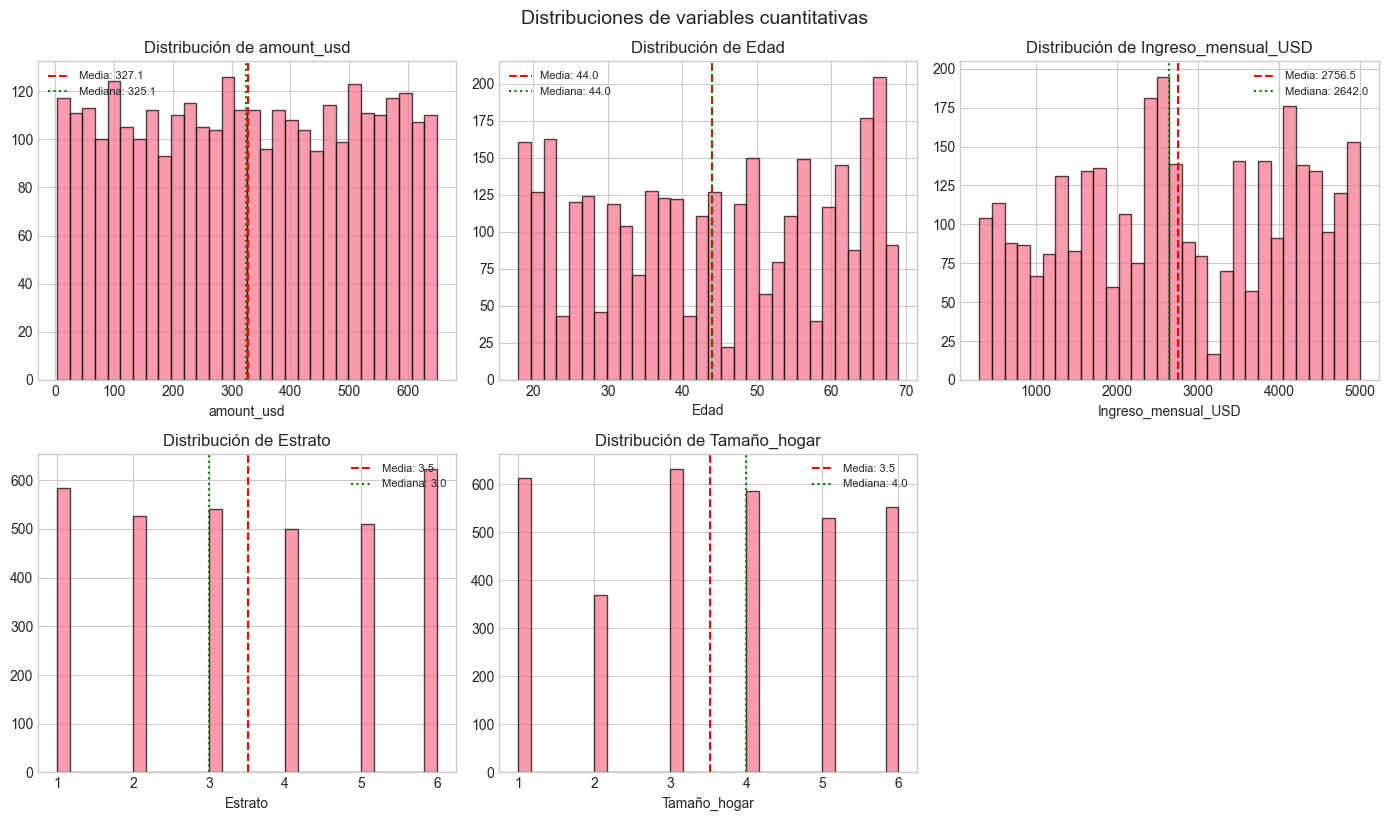

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(columnas_numericas):
    axes[i].hist(df[col].dropna(), bins=30, edgecolor='black', alpha=0.7)
    axes[i].set_title(f'Distribución de {col}')
    axes[i].set_xlabel(col)
    axes[i].axvline(df[col].mean(), color='red', linestyle='--', label=f'Media: {df[col].mean():.1f}')
    axes[i].axvline(df[col].median(), color='green', linestyle=':', label=f'Mediana: {df[col].median():.1f}')
    axes[i].legend(fontsize=8)

if len(columnas_numericas) < 6:
    axes[-1].axis('off')
plt.tight_layout()
plt.suptitle('Distribuciones de variables cuantitativas', y=1.02, fontsize=14)
plt.show()

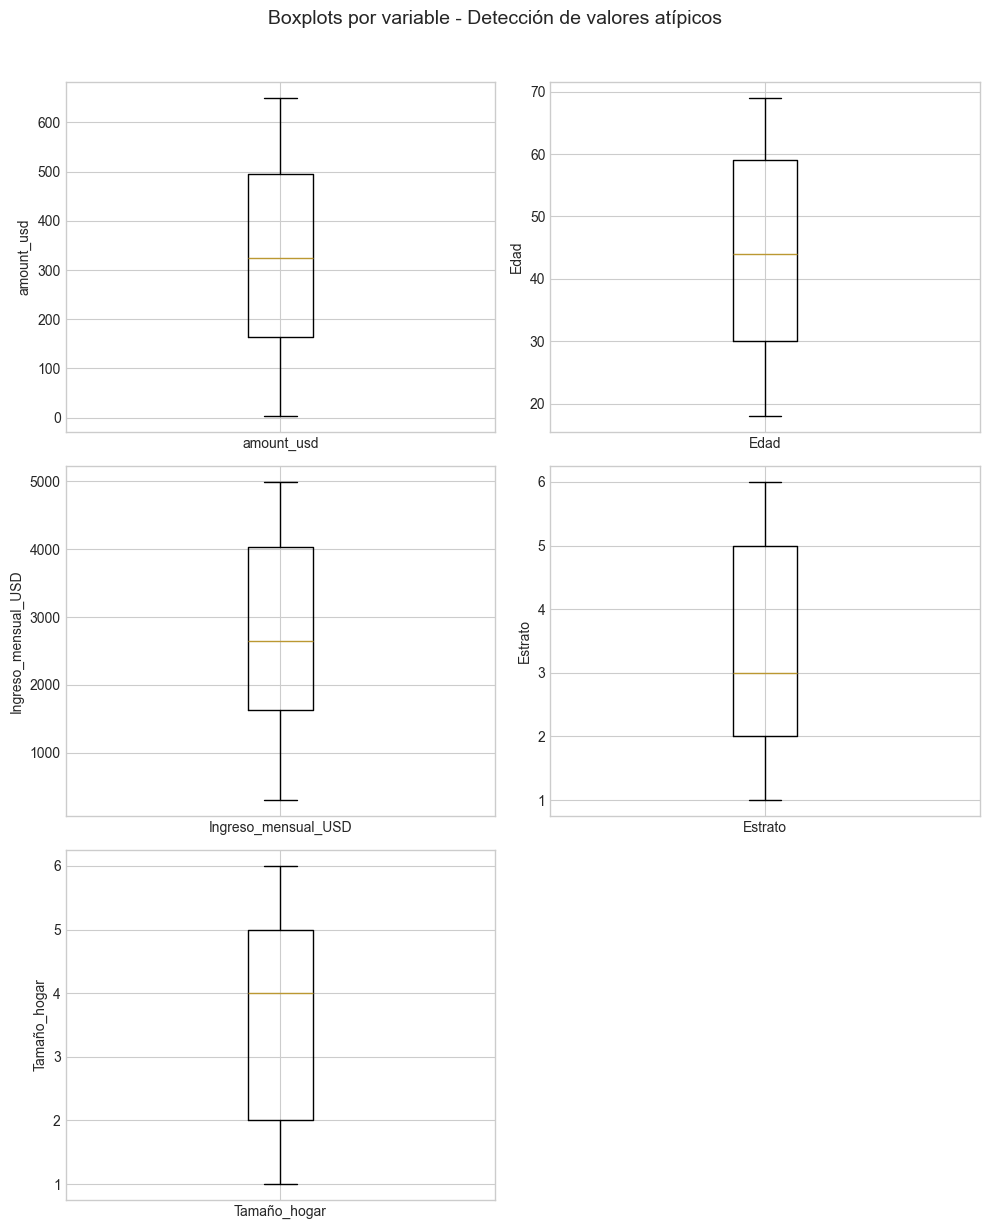

In [23]:
# Boxplot por variable (uno por cada variable cuantitativa)
n_vars = len(columnas_numericas)
n_cols = 2
n_rows = (n_vars + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 4 * n_rows))
axes = np.array(axes).flatten() if n_vars > 1 else [axes]

for i, col in enumerate(columnas_numericas):
    axes[i].boxplot(df[col].dropna(), vert=True)
    axes[i].set_ylabel(col)
    axes[i].set_xticklabels([col])

# Ocultar subplots vacíos
for j in range(n_vars, len(axes)):
    axes[j].axis('off')

plt.suptitle('Boxplots por variable - Detección de valores atípicos', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

### 3.3 Insights para toma de decisiones - Variables cuantitativas

In [11]:
print("\n" + "="*60)
print("INSIGHTS PARA TOMA DE DECISIONES - VARIABLES CUANTITATIVAS")
print("="*60)

if 'amount_usd' in df.columns:
    print(f"\n• Ticket promedio de transacción: ${df['amount_usd'].mean():.2f} USD")
    print(f"• Mediana del ticket: ${df['amount_usd'].median():.2f} USD")
    print(f"• 25% de transacciones son menores a ${df['amount_usd'].quantile(0.25):.2f} USD")
    print(f"• 25% de transacciones superan ${df['amount_usd'].quantile(0.75):.2f} USD")

if 'Edad' in df.columns:
    print(f"\n• Edad promedio de la población: {df['Edad'].mean():.1f} años")
    print(f"• Rango de edad: {df['Edad'].min():.0f} - {df['Edad'].max():.0f} años")

if 'Ingreso_mensual_USD' in df.columns:
    print(f"\n• Ingreso mensual promedio: ${df['Ingreso_mensual_USD'].mean():.0f} USD")
    print(f"• Ingreso mediano: ${df['Ingreso_mensual_USD'].median():.0f} USD")

if 'Estrato' in df.columns:
    print(f"\n• Estrato predominante (moda): {df['Estrato'].mode().values[0]}")
    print(f"• Estrato promedio: {df['Estrato'].mean():.2f}")

# Tamaño del hogar (última columna numérica)
print(f"\n• Tamaño promedio del hogar: {df[columnas_numericas[-1]].mean():.2f} personas")
print(f"• Hogares más comunes: {df[columnas_numericas[-1]].mode().values[0]} personas")


INSIGHTS PARA TOMA DE DECISIONES - VARIABLES CUANTITATIVAS

• Ticket promedio de transacción: $327.13 USD
• Mediana del ticket: $325.05 USD
• 25% de transacciones son menores a $163.22 USD
• 25% de transacciones superan $494.50 USD

• Edad promedio de la población: 44.0 años
• Rango de edad: 18 - 69 años

• Ingreso mensual promedio: $2756 USD
• Ingreso mediano: $2642 USD

• Estrato predominante (moda): 6
• Estrato promedio: 3.52

• Tamaño promedio del hogar: 3.52 personas
• Hogares más comunes: 3 personas


## 4. Análisis de variables cualitativas

### 4.1 Tablas de frecuencias

In [12]:
print("="*60)
print("FRECUENCIAS Y PORCENTAJES - VARIABLES CUALITATIVAS")
print("="*60)

for col in columnas_cualitativas[:6]:  # Primeras 6 para no saturar
    freq = df[col].value_counts()
    pct = df[col].value_counts(normalize=True) * 100
    tabla = pd.DataFrame({'Frecuencia': freq, 'Porcentaje (%)': pct.round(2)})
    print(f"\n--- {col} ---")
    print(tabla)

FRECUENCIAS Y PORCENTAJES - VARIABLES CUALITATIVAS

--- channel ---
         Frecuencia  Porcentaje (%)
channel                            
App            1111           33.83
Tienda         1087           33.10
Online         1086           33.07

--- category ---
             Frecuencia  Porcentaje (%)
category                               
Belleza             587           17.87
Hogar               553           16.84
Deportes            553           16.84
Moda                542           16.50
Electrónica         529           16.11
Mercado             520           15.83

--- payment_method ---
                   Frecuencia  Porcentaje (%)
payment_method                               
Crédito                   844           25.70
Efectivo                  837           25.49
Débito                    807           24.57
Billetera digital         796           24.24

--- Género ---
            Frecuencia  Porcentaje (%)
Género                                
Mujer             16

In [13]:
# Resto de variables cualitativas
for col in columnas_cualitativas[6:]:
    freq = df[col].value_counts()
    pct = df[col].value_counts(normalize=True) * 100
    tabla = pd.DataFrame({'Frecuencia': freq, 'Porcentaje (%)': pct.round(2)})
    print(f"\n--- {col} ---")
    print(tabla)


--- Profesión ---
               Frecuencia  Porcentaje (%)
Profesión                                
Comerciante           474           14.43
Técnico               450           13.70
Docente               443           13.49
Médico                432           13.15
Abogado               391           11.91
Diseñador             366           11.14
Administrador         365           11.11
Ingeniero             363           11.05

--- Estado_civil ---
              Frecuencia  Porcentaje (%)
Estado_civil                            
Unión libre          824           25.09
Soltero              670           20.40
Divorciado           640           19.49
Viudo                585           17.81
Casado               565           17.20

--- Ciclo_vida_familiar ---
                     Frecuencia  Porcentaje (%)
Ciclo_vida_familiar                            
Familia con hijos           911           27.74
Nido vacío                  800           24.36
Joven soltero               794

### 4.2 Visualizaciones - Variables cualitativas

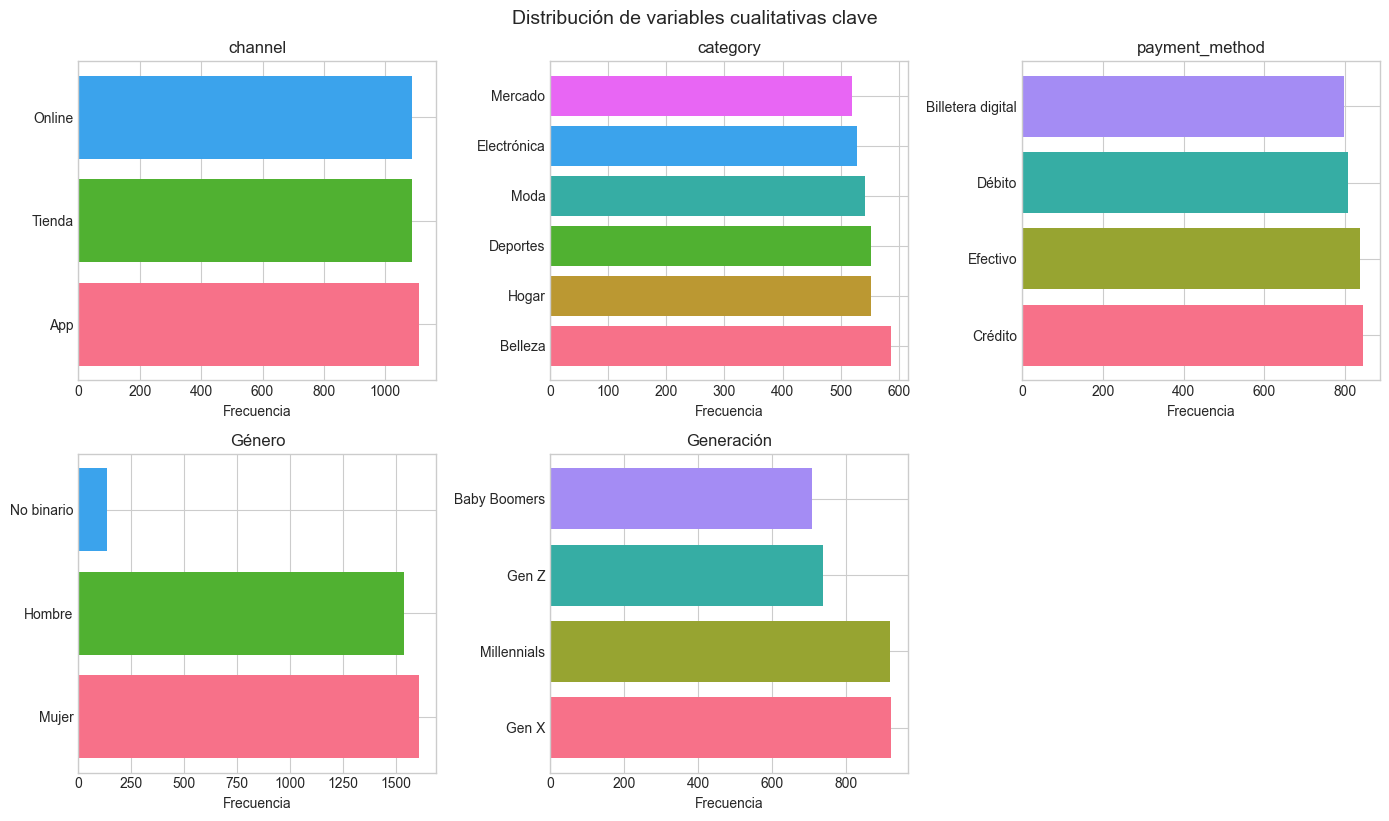

In [14]:
# Gráficos de barras para las principales variables cualitativas
vars_principales = ['channel', 'category', 'payment_method', 'Género', 'Generación']
vars_principales = [v for v in vars_principales if v in df.columns]
if len(vars_principales) < 5:
    vars_principales = columnas_cualitativas[:5]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(vars_principales):
    counts = df[col].value_counts()
    axes[i].barh(counts.index.astype(str), counts.values, color=sns.color_palette('husl', len(counts)))
    axes[i].set_title(col)
    axes[i].set_xlabel('Frecuencia')

axes[-1].axis('off')
plt.tight_layout()
plt.suptitle('Distribución de variables cualitativas clave', y=1.02, fontsize=14)
plt.show()

### 4.3 Caracterización del perfil de la población

In [15]:
print("\n" + "="*60)
print("CARACTERIZACIÓN DEL PERFIL DE LA POBLACIÓN")
print("="*60)

genero_col = [c for c in df.columns if 'nero' in c or 'Género' in c][0] if any('nero' in str(c) for c in df.columns) else columnas_cualitativas[3]
gen_col = [c for c in df.columns if 'Generaci' in c or 'Generación' in c][0] if any('Generaci' in str(c) for c in df.columns) else columnas_cualitativas[-1]

print(f"\n• Canal más utilizado: {df['channel'].mode().values[0]}" if 'channel' in df.columns else '')
print(f"• Categoría más comprada: {df['category'].mode().values[0]}" if 'category' in df.columns else '')
print(f"• Método de pago predominante: {df['payment_method'].mode().values[0]}" if 'payment_method' in df.columns else '')
print(f"• Distribución por género: {df[genero_col].value_counts().to_dict()}")
print(f"• Generación predominante: {df[gen_col].mode().values[0]}")
print(f"\n• Total de transacciones analizadas: {len(df):,}")
print(f"• Clientes únicos: {df['key_user'].nunique():,}" if 'key_user' in df.columns else '')


CARACTERIZACIÓN DEL PERFIL DE LA POBLACIÓN

• Canal más utilizado: App
• Categoría más comprada: Belleza
• Método de pago predominante: Crédito
• Distribución por género: {'Mujer': 1611, 'Hombre': 1539, 'No binario': 134}
• Generación predominante: Gen X

• Total de transacciones analizadas: 3,284
• Clientes únicos: 500


## 5. Análisis cruzado para toma de decisiones

In [16]:
# Ticket promedio por canal
if 'amount_usd' in df.columns and 'channel' in df.columns:
    ticket_canal = df.groupby('channel')['amount_usd'].agg(['mean', 'median', 'count']).round(2)
    ticket_canal.columns = ['Ticket Promedio (USD)', 'Ticket Mediano (USD)', 'N° Transacciones']
    print("Ticket promedio por canal de venta:")
    print(ticket_canal)
    print()

Ticket promedio por canal de venta:
         Ticket Promedio (USD)  Ticket Mediano (USD)  N° Transacciones
channel                                                               
App                     323.90                318.33              1111
Online                  331.08                333.31              1086
Tienda                  326.49                322.76              1087



In [17]:
# Ticket promedio por categoría de producto
if 'amount_usd' in df.columns and 'category' in df.columns:
    ticket_cat = df.groupby('category')['amount_usd'].agg(['mean', 'median', 'count']).round(2)
    ticket_cat.columns = ['Ticket Promedio (USD)', 'Ticket Mediano (USD)', 'N° Transacciones']
    print("Ticket promedio por categoría:")
    print(ticket_cat.sort_values('Ticket Promedio (USD)', ascending=False))
    print()

Ticket promedio por categoría:
             Ticket Promedio (USD)  Ticket Mediano (USD)  N° Transacciones
category                                                                  
Mercado                     338.92                353.46               520
Electrónica                 335.23                329.25               529
Hogar                       332.55                331.91               553
Belleza                     322.72                317.92               587
Moda                        318.46                326.43               542
Deportes                    316.06                294.21               553



In [18]:
# Ingreso promedio por generación
ingreso_col = [c for c in df.columns if 'Ingreso' in c][0]
gen_col = [c for c in df.columns if 'Generaci' in str(c)][0]

ingreso_generacion = df.groupby(gen_col)[ingreso_col].agg(['mean', 'median', 'count']).round(0)
ingreso_generacion.columns = ['Ingreso Promedio (USD)', 'Ingreso Mediano (USD)', 'N']
print("Ingreso mensual por generación:")
print(ingreso_generacion)

Ingreso mensual por generación:
              Ingreso Promedio (USD)  Ingreso Mediano (USD)    N
Generación                                                      
Baby Boomers                 2542.00                2431.00  706
Gen X                        2926.00                2780.00  921
Gen Z                        2816.00                2854.00  738
Millennials                  2704.00                2637.00  919


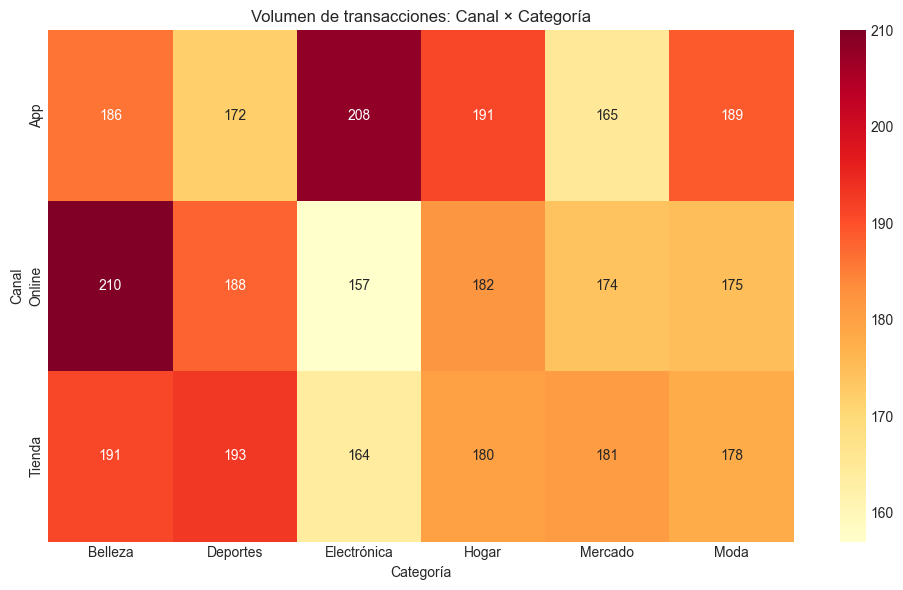

In [19]:
# Heatmap: Canal vs Categoría (volumen de transacciones)
tabla_cruzada = pd.crosstab(df['channel'], df['category'])

plt.figure(figsize=(10, 6))
sns.heatmap(tabla_cruzada, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Volumen de transacciones: Canal × Categoría')
plt.xlabel('Categoría')
plt.ylabel('Canal')
plt.tight_layout()
plt.show()

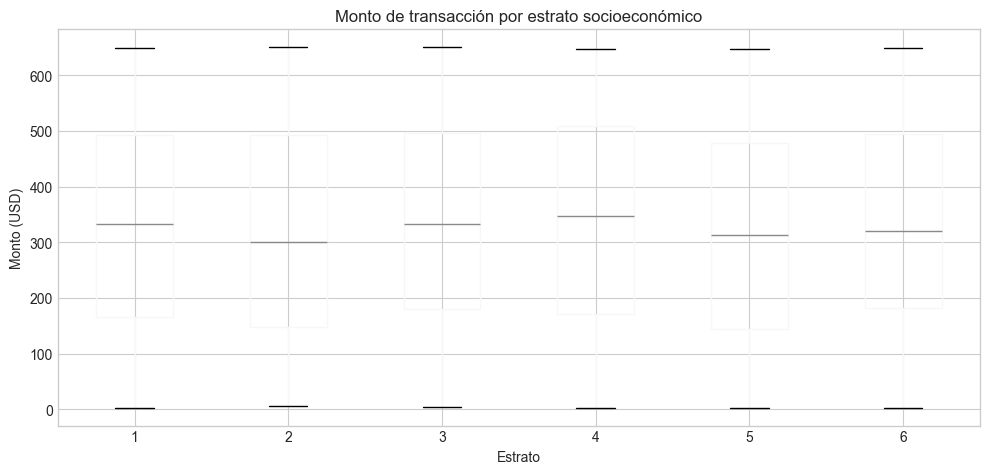

In [20]:
# Distribución del gasto por estrato socioeconómico
estrato_col = [c for c in df.columns if 'Estrato' in c][0]

fig, ax = plt.subplots(figsize=(10, 5))
df.boxplot(column='amount_usd', by=estrato_col, ax=ax)
plt.suptitle('')
plt.title('Monto de transacción por estrato socioeconómico')
plt.xlabel('Estrato')
plt.ylabel('Monto (USD)')
plt.tight_layout()
plt.show()

## 6. Resumen ejecutivo y recomendaciones

In [21]:
print("\n" + "="*70)
print("RESUMEN EJECUTIVO - CARACTERIZACIÓN DE LA POBLACIÓN")
print("="*70)

print("""
1. PERFIL SOCIODEMOGRÁFICO:
   - Edad promedio y rango
   - Distribución por género y generación
   - Nivel de ingreso y estrato predominante
   - Tamaño típico del hogar

2. COMPORTAMIENTO DE COMPRA:
   - Canal preferido (Online, Tienda, App)
   - Categorías más demandadas
   - Ticket promedio y variabilidad
   - Método de pago predominante

3. RECOMENDACIONES PARA TOMA DE DECISIONES:
   - Segmentar ofertas según canal y categoría
   - Considerar el perfil generacional en estrategias de marketing
   - Ajustar métodos de pago según preferencias
   - Orientar inventario según categorías de mayor ticket
""")

ingreso_col = [c for c in df.columns if 'Ingreso' in str(c)][0]
print("\nMétricas clave calculadas:")
print(f"  • Transacciones: {len(df):,}")
print(f"  • Ticket promedio: ${df['amount_usd'].mean():.2f} USD")
print(f"  • Ingreso promedio: ${df[ingreso_col].mean():.0f} USD")
print(f"  • Canal líder: {df['channel'].mode().values[0]}")
print(f"  • Categoría líder: {df['category'].mode().values[0]}")


RESUMEN EJECUTIVO - CARACTERIZACIÓN DE LA POBLACIÓN

1. PERFIL SOCIODEMOGRÁFICO:
   - Edad promedio y rango
   - Distribución por género y generación
   - Nivel de ingreso y estrato predominante
   - Tamaño típico del hogar

2. COMPORTAMIENTO DE COMPRA:
   - Canal preferido (Online, Tienda, App)
   - Categorías más demandadas
   - Ticket promedio y variabilidad
   - Método de pago predominante

3. RECOMENDACIONES PARA TOMA DE DECISIONES:
   - Segmentar ofertas según canal y categoría
   - Considerar el perfil generacional en estrategias de marketing
   - Ajustar métodos de pago según preferencias
   - Orientar inventario según categorías de mayor ticket


Métricas clave calculadas:
  • Transacciones: 3,284
  • Ticket promedio: $327.13 USD
  • Ingreso promedio: $2756 USD
  • Canal líder: App
  • Categoría líder: Belleza
